# 02 - Cleaning and feature selection (binary task)
**Task**: `CONFIRMED` (planet) vs `FALSE POSITIVE`. The 2,367 `CANDIDATE` objects have no final verdict, so they are **excluded** (they would be label noise).

Every decision is logged in `results/cleaning_log.csv`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
raw = pd.read_csv("../data/exoplanets.csv")      # original, never modified
df = raw.copy()
log = []          # change log: (step, detail, rows_after, cols_after)
def note(step, detail): log.append({"step": step, "detail": detail, "rows": len(df), "cols": df.shape[1]})
note("load", "original KOI cumulative table")
print(df.shape)

(9564, 49)


## 1. Binary target
We drop `CANDIDATE` and encode `CONFIRMED = 1`, `FALSE POSITIVE = 0`.

In [2]:
df = df[df["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
df["target"] = (df["koi_disposition"] == "CONFIRMED").astype(int)
note("binary target", "dropped CANDIDATE; CONFIRMED=1, FALSE POSITIVE=0")
print(df["target"].value_counts().rename({1: "CONFIRMED", 0: "FALSE POSITIVE"}))
print("Positive rate:", round(df["target"].mean(), 3))

target
FALSE POSITIVE    4840
CONFIRMED         2357
Name: count, dtype: int64
Positive rate: 0.327


## 2. Columns removed, with the reason
Leakage is the central risk: some columns are produced by the same vetting process that gives the label, so a model would just read the answer.

In [3]:
drop = {
 "kepid": "identifier (kept aside only to group rows of the same star during validation)",
 "kepoi_name": "identifier", "kepler_name": "identifier AND only filled for confirmed planets (leaks the label)",
 "koi_disposition": "original label (replaced by `target`)",
 "koi_pdisposition": "LEAKAGE: disposition from the Kepler pipeline, almost the label",
 "koi_score": "LEAKAGE: vetting confidence score computed for the disposition",
 "koi_fpflag_nt": "LEAKAGE: false-positive flag from vetting (also contains an invalid value 465)",
 "koi_fpflag_ss": "LEAKAGE: false-positive flag from vetting",
 "koi_fpflag_co": "LEAKAGE: false-positive flag from vetting",
 "koi_fpflag_ec": "LEAKAGE: false-positive flag from vetting",
 "koi_teq_err1": "100% missing", "koi_teq_err2": "100% missing",
 "koi_tce_delivname": "pipeline version label, not a physical measurement",
 "koi_time0bk": "arbitrary transit epoch (depends on observation start, not on the object's nature)",
 "ra": "sky position, not a physical property of the signal", "dec": "sky position, not a physical property of the signal",
}
err_cols = [c for c in df.columns if "_err" in c and c not in drop]
for c in err_cols: drop[c] = "uncertainty column (kept out: strongly correlated with its measurement, adds noise)"
keep_id = df[["kepid", "target"]].copy()
pd.DataFrame({"column": list(drop), "reason": list(drop.values())}).to_csv("../results/columns_dropped.csv", index=False)
features = [c for c in df.columns if c not in drop and c not in ("target",)]
note("column selection", f"kept {len(features)} physical features, dropped {len(drop)} columns (leakage, ids, empty, uncertainties)")
print(len(features), "features kept:"); print(features)

13 features kept:
['koi_period', 'koi_impact', 'koi_duration', 'koi_depth', 'koi_prad', 'koi_teq', 'koi_insol', 'koi_model_snr', 'koi_tce_plnt_num', 'koi_steff', 'koi_slogg', 'koi_srad', 'koi_kepmag']


## 3. Missing values and outliers on the kept features

In [4]:
miss = (df[features].isna().mean() * 100).round(2).sort_values(ascending=False)
print(miss[miss > 0].to_string())
print("\nSkewness:"); print(df[features].skew().round(1).sort_values(ascending=False).to_string())
print("\nMax values (extreme outliers):"); print(df[["koi_prad", "koi_depth", "koi_insol", "koi_period"]].max())

koi_tce_plnt_num    3.95
koi_prad            3.58
koi_depth           3.58
koi_teq             3.58
koi_impact          3.58
koi_srad            3.58
koi_slogg           3.58
koi_model_snr       3.58
koi_steff           3.58
koi_insol           3.04
koi_kepmag          0.01

Skewness:
koi_prad            52.3
koi_insol           43.5
koi_impact          24.5
koi_srad            19.9
koi_duration         6.0
koi_model_snr        4.6
koi_depth            4.5
koi_tce_plnt_num     3.9
koi_teq              3.4
koi_period           3.0
koi_steff            0.9
koi_kepmag          -0.7
koi_slogg           -3.5

Max values (extreme outliers):
koi_prad      2.003460e+05
koi_depth     1.540000e+06
koi_insol     1.094755e+07
koi_period    1.071233e+03
dtype: float64


**Decisions**
- Missing values are **not** imputed here (3.8% at most). Imputation is a modelling choice compared in notebook 03, learned **inside each cross-validation fold** to avoid leakage.
- Extreme outliers (e.g. planet radius of 200,346 Earth radii) are physically absurd but they are mostly false positives, which is informative, so rows are **kept**. Heavy skew is handled by a `log1p` transform in the model pipeline.
- Multiple KOIs can share the same star (`kepid`): notebook 03 splits by star so one star never appears in both train and test.

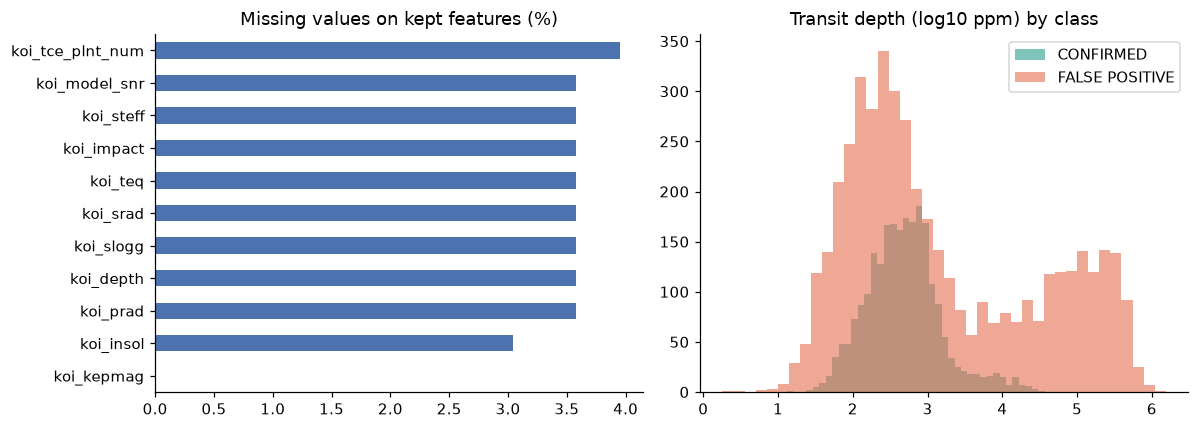

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
miss[miss > 0].sort_values().plot.barh(ax=ax[0], color="#4c72b0"); ax[0].set_title("Missing values on kept features (%)")
for lab, col in [(1, "#2a9d8f"), (0, "#e76f51")]:
    ax[1].hist(np.log10(df.loc[df.target == lab, "koi_depth"].dropna() + 1), bins=40, alpha=.6, color=col,
               label="CONFIRMED" if lab else "FALSE POSITIVE")
ax[1].set_title("Transit depth (log10 ppm) by class"); ax[1].legend()
plt.tight_layout(); plt.savefig("../results/figures/cleaning_overview.png"); plt.show()

## 4. Duplicates and export

In [6]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Stars with several KOIs:", (df.groupby("kepid").size() > 1).sum(), "of", df.kepid.nunique())
out = pd.concat([keep_id, df[features]], axis=1)
note("export", "data/processed/koi_binary_clean.csv (kepid, target, features)")
out.to_csv("../data/processed/koi_binary_clean.csv", index=False)
pd.DataFrame(log).to_csv("../results/cleaning_log.csv", index=False)
print(out.shape); pd.DataFrame(log)

Exact duplicate rows: 0
Stars with several KOIs: 586 of 6353
(7197, 15)


,step,detail,rows,cols
0,load,original KOI cumulative table,9564,49
1,binary target,"dropped CANDIDATE; CONFIRMED=1, FALSE POSITIVE=0",7197,50
2,column selection,"kept 13 physical features, dropped 36 columns ...",7197,50
3,export,"data/processed/koi_binary_clean.csv (kepid, ta...",7197,50
